In [1]:
!pip3 install -U ucimlrepo

# **Data**

For this notebook, the data used is the Bank Marketing dataset from the UC Irvine Machine Learning Repository (https://archive.ics.uci.edu/dataset/222/bank+marketing).


The objective is to predict whether or not a client will subscribe to a bank term deposit based on prior data.

**This is a straightforward supervised machine learning classification task:** given past data, we want to train a model to predict a binary outcome on testing data.  

In [2]:
from ucimlrepo import list_available_datasets
#These are the available datasets from UC Irvine ML Repo
list_available_datasets()

-------------------------------------
The following datasets are available:
-------------------------------------
Dataset Name                                                                            ID    
------------                                                                            --    
Abalone                                                                                 1     
Adult                                                                                   2     
Annealing                                                                               3     
Audiology (Standardized)                                                                8     
Auto MPG                                                                                9     
Automobile                                                                              10    
Balance Scale                                                                           12    
Balloons                       

**Extra Info about the ucimlrepo package:** (https://github.com/uci-ml-repo/ucimlrepo)



#**Exploratory Data Analysis (EDA)**

First, we conducted EDA, where we explore, summarise and visualise the data to understand its structure, detect patterns etc.

Here this involves:
- Finding the unique values in each column
- Finding the distribution of the target label
  - to identify any class imbalance
- Finding the distributions of the numerical variables and the counts of categorical variables
  - to determine any biases in the data
- Encoding categorical and binary variables
  - using label encoding, one-hot encoding

In [3]:
#Getting the data
from ucimlrepo import fetch_ucirepo

# Import dataset ()
df = fetch_ucirepo(id=222)

# Return dataframe of features and targets
X = df.data.features
y = df.data.targets

# Access metadata for information about the dataset
print(df.metadata.uci_id)
print(df.metadata.num_instances)
print(df.metadata.additional_info.summary)

# Access variable info
print(df.variables)

222
45211
The data is related with direct marketing campaigns of a Portuguese banking institution. The marketing campaigns were based on phone calls. Often, more than one contact to the same client was required, in order to access if the product (bank term deposit) would be ('yes') or not ('no') subscribed. 

There are four datasets: 
1) bank-additional-full.csv with all examples (41188) and 20 inputs, ordered by date (from May 2008 to November 2010), very close to the data analyzed in [Moro et al., 2014]
2) bank-additional.csv with 10% of the examples (4119), randomly selected from 1), and 20 inputs.
3) bank-full.csv with all examples and 17 inputs, ordered by date (older version of this dataset with less inputs). 
4) bank.csv with 10% of the examples and 17 inputs, randomly selected from 3 (older version of this dataset with less inputs). 
The smallest datasets are provided to test more computationally demanding machine learning algorithms (e.g., SVM). 

The classification goal is to

In [4]:
#Find the unique values for each feature
for column in X.columns:
    print(f"Unique values for '{column}': {X[column].unique()}\n")

Unique values for 'age': [58 44 33 47 35 28 42 43 41 29 53 57 51 45 60 56 32 25 40 39 52 46 36 49
 59 37 50 54 55 48 24 38 31 30 27 34 23 26 61 22 21 20 66 62 83 75 67 70
 65 68 64 69 72 71 19 76 85 63 90 82 73 74 78 80 94 79 77 86 95 81 18 89
 84 87 92 93 88]

Unique values for 'job': ['management' 'technician' 'entrepreneur' 'blue-collar' nan 'retired'
 'admin.' 'services' 'self-employed' 'unemployed' 'housemaid' 'student']

Unique values for 'marital': ['married' 'single' 'divorced']

Unique values for 'education': ['tertiary' 'secondary' nan 'primary']

Unique values for 'default': ['no' 'yes']

Unique values for 'balance': [ 2143    29     2 ...  8205 14204 16353]

Unique values for 'housing': ['yes' 'no']

Unique values for 'loan': ['no' 'yes']

Unique values for 'contact': [nan 'cellular' 'telephone']

Unique values for 'day_of_week': [ 5  6  7  8  9 12 13 14 15 16 19 20 21 23 26 27 28 29 30  2  3  4 11 17
 18 24 25  1 10 22 31]

Unique values for 'month': ['may' 'jun' 'jul' 'au

y  
no     88.30152
yes    11.69848
Name: proportion, dtype: float64


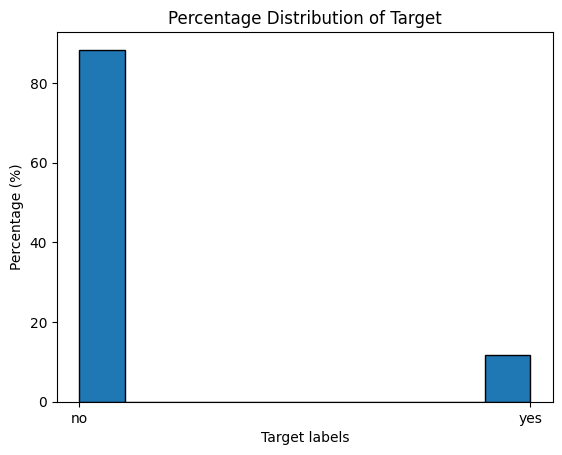

In [5]:
#Find distribution of target/ label
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

weights = np.ones_like(df.data.targets)/ len(df.data.targets) * 100

plt.hist(df.data.targets, weights=weights, edgecolor='k')
plt.xlabel('Target labels'); plt.ylabel('Percentage (%)'); plt.title('Percentage Distribution of Target')
print(df.data.targets.value_counts(normalize=True)*100) # normalize=True*100 gives percentages

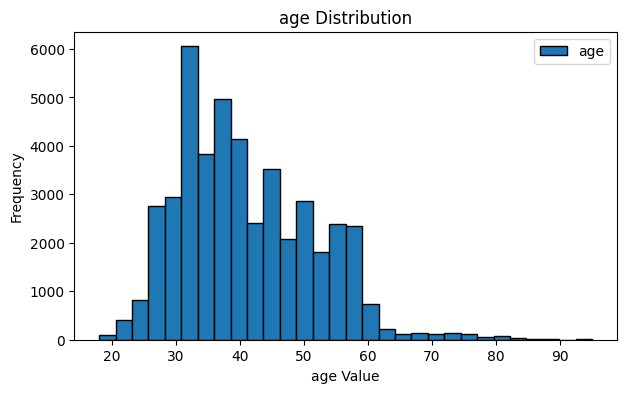

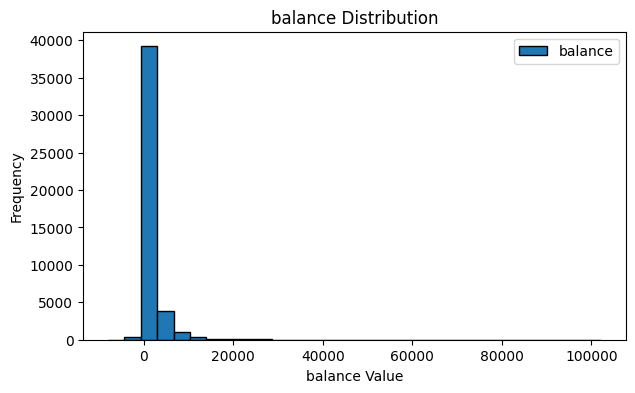

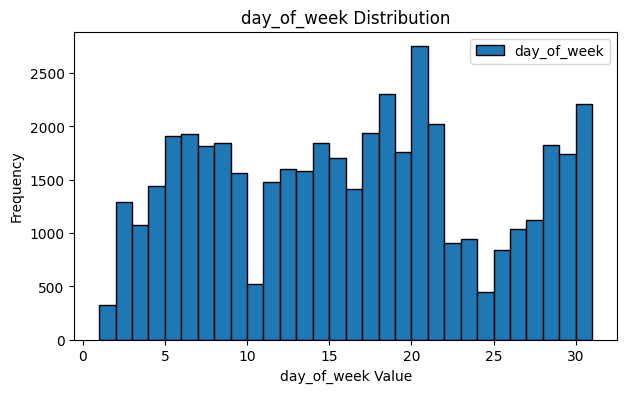

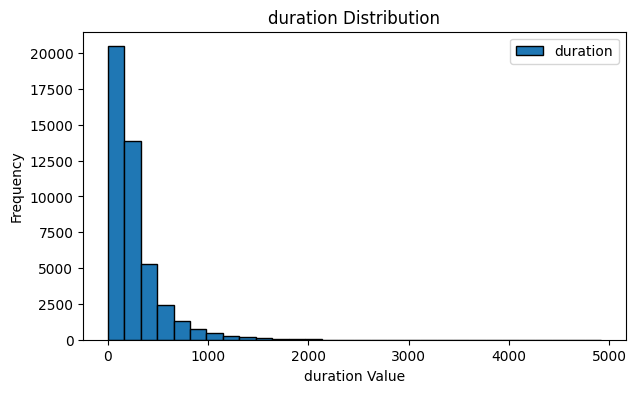

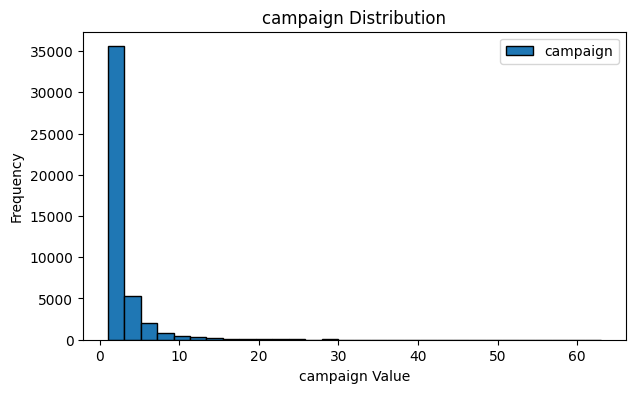

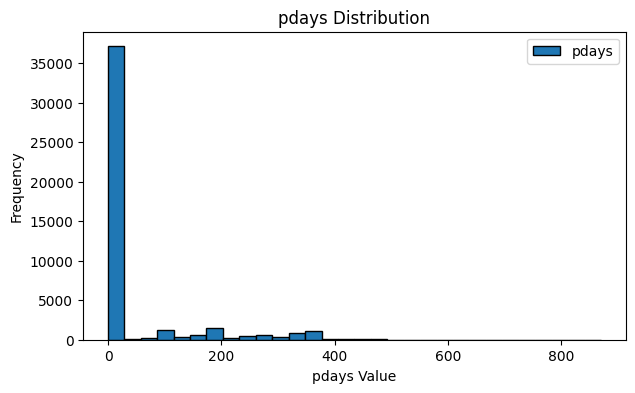

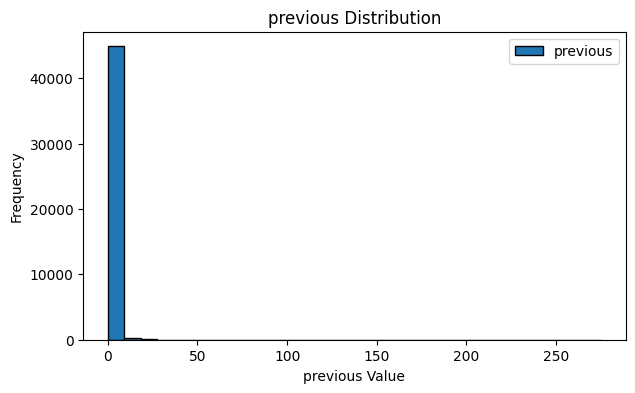

In [6]:
#Find out distribution of numerical variables, find counts for categorical variables
#1. Find distribution of numeric variables
import pandas as pd
import numpy as np

# Select only numerical columns directly
numeric_cols = X.select_dtypes(include=['number']).columns

for col in numeric_cols:
    plt.figure(figsize=(7,4))
    # Use hist instead of bar to automatically bin and calculate frequencies
    plt.hist(X[col].dropna(), bins=30, edgecolor='k', label='{}'.format(col))
    plt.xlabel('{} Value'.format(col))
    plt.ylabel('Frequency')
    plt.title('{} Distribution'.format(col))
    plt.legend()
    plt.show()

/tmp/ipykernel_1416/3896740161.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


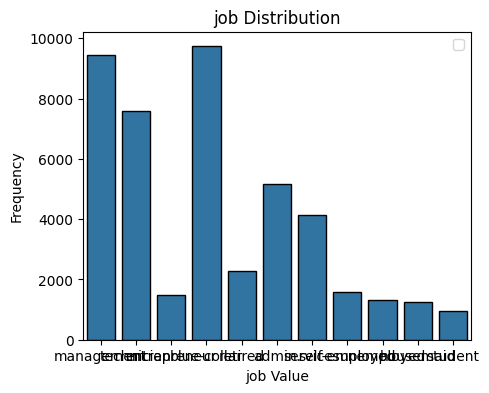

/tmp/ipykernel_1416/3896740161.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


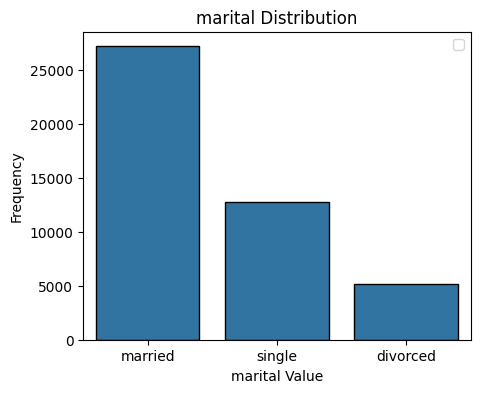

/tmp/ipykernel_1416/3896740161.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


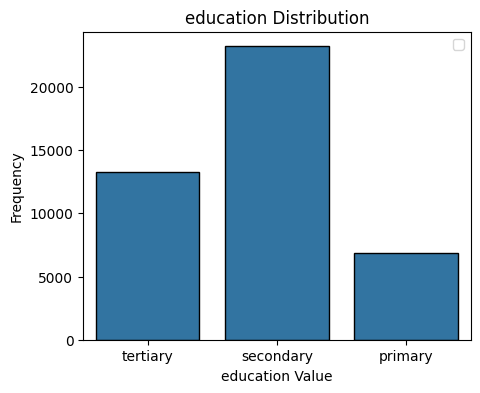

/tmp/ipykernel_1416/3896740161.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


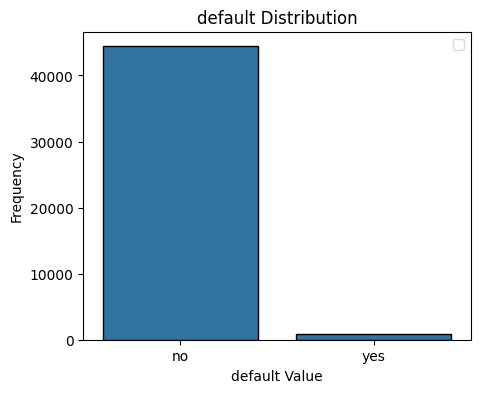

/tmp/ipykernel_1416/3896740161.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


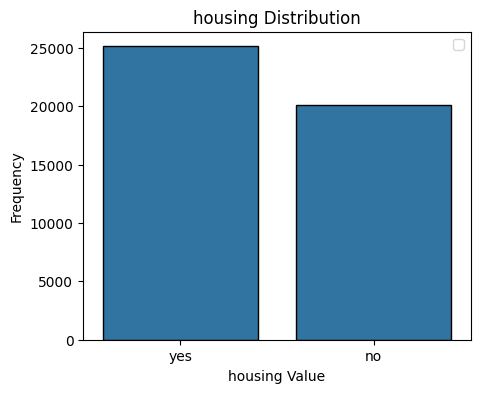

/tmp/ipykernel_1416/3896740161.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


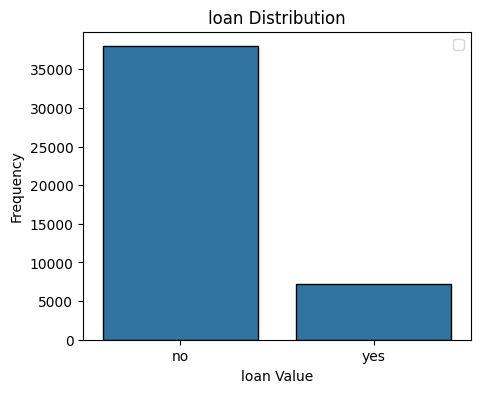

/tmp/ipykernel_1416/3896740161.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


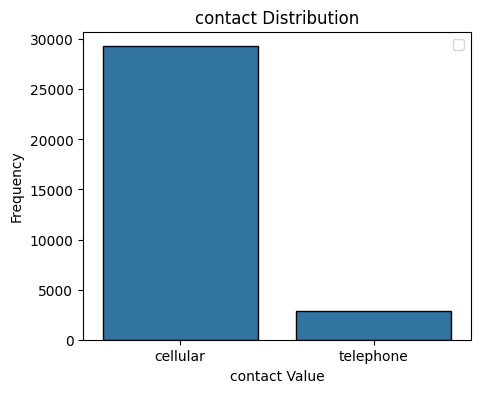

/tmp/ipykernel_1416/3896740161.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


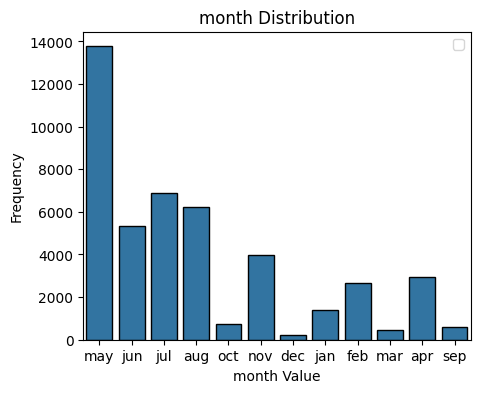

/tmp/ipykernel_1416/3896740161.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


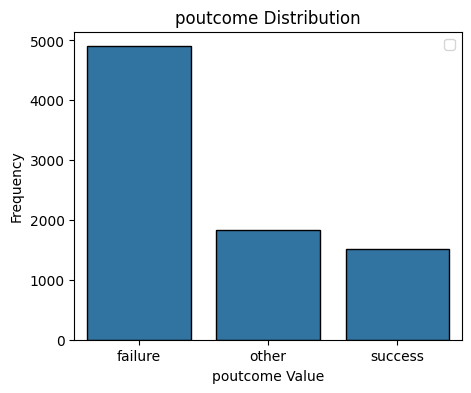

In [7]:
#2. Find counts for categorical variables
cat_cols = X.select_dtypes(include=['category','object']).columns

for col in cat_cols:
    plt.figure(figsize=(5,4))
    sns.countplot(data=X, x=col, edgecolor='k') #seaborn can count values automatically (no need for .value_counts)
    plt.xlabel('{} Value'.format(col))
    plt.ylabel('Frequency')
    plt.title('{} Distribution'.format(col))
    plt.legend()
    plt.show()

#**Data Pre-processing**
Next, we need to process the data:
- handle any missing values
- encode variables (one-hot, label)

In [8]:
#Create checkpoint copy of X and y
X_clean = X.copy()
y_clean = y.copy()

#Find missing values
rows_with_nan = X_clean[X_clean.isna().any(axis=1)]

print(f"Number of rows with NaNs: {len(rows_with_nan)}")

Number of rows with NaNs: 37369


**For the above...**\
 the values that are Nan for job, education, contact and poutcome. It would remove a lot of data if we were to drop all rows with Nan (particularly for poutcome), and as they aren't numerical variables, we can't really impute/ interpolate.\
 \
 Therefore, we just map a new variable, 'unknown' to the data. The data will still be kept and the model won't train on features that are uninformative anyway (eg. poutcome, which has ~37k Nan)\
\
For reference:
- contact = contact communication type (eg. 'cellular', 'telephone')
- poutcome = outcome of the previous marketing campaign (eg. 'other', 'failure','success')


In [9]:
#Using fillna to fill all Nan with "unknown"
X_clean.fillna('unknown', inplace=True)
len(X_clean[X_clean.isin(['unknown']).any(axis=1)])

37369

> No need to **find outliers** as the model will deal with it

> No need to **normalise/ standardise data** as using tree-based models
>> If using distance-based/ gradient-based models (eg. Logistic Regression, KNN, SVM, NN) then feature scaling is mandatory
>>> required as these models would treat large-scale features as more important because of their larger numeric values

In [10]:
X_clean.head()

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown


In [11]:
#Drop feature 'duration'
##The dataset documentation says that duration is known to heavily influence the output target
### They suggest to remove it as it would be too much of a predictor (results in target leakage)
X_clean.drop(columns='duration', inplace=True)
X_clean.columns #check if the column was dropped

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day_of_week', 'month', 'campaign', 'pdays',
       'previous', 'poutcome'],
      dtype='object')

In [12]:
# Encode categorical variables
# 1. Encoding binary (yes/no) variables in X to 1/0
binary_cols = [col for col in X_clean.columns if X_clean[col].nunique() == 2]
print("Detected binary columns in X:", binary_cols)

for col in binary_cols:
    X_clean[col] = X_clean[col].map({'yes': 1, 'no': 0})

# 2. Encoding the target variable y to 1/0
y_clean['y'] = y_clean['y'].map({'yes': 1, 'no': 0})

print(X_clean.head())
print(y_clean.head())

Detected binary columns in X: ['default', 'housing', 'loan']
   age           job  marital  education  default  balance  housing  loan  \
0   58    management  married   tertiary        0     2143        1     0   
1   44    technician   single  secondary        0       29        1     0   
2   33  entrepreneur  married  secondary        0        2        1     1   
3   47   blue-collar  married    unknown        0     1506        1     0   
4   33       unknown   single    unknown        0        1        0     0   

   contact  day_of_week month  campaign  pdays  previous poutcome  
0  unknown            5   may         1     -1         0  unknown  
1  unknown            5   may         1     -1         0  unknown  
2  unknown            5   may         1     -1         0  unknown  
3  unknown            5   may         1     -1         0  unknown  
4  unknown            5   may         1     -1         0  unknown  
   y
0  0
1  0
2  0
3  0
4  0


In [13]:
#Use label encoding for 'month'
month_map = {
    'may': 5,
    'jun': 6,
    'jul': 7,
    'aug': 8,
    'sep': 9,
    'oct': 10,
    'nov': 11,
    'dec': 12,
    'jan': 1,
    'feb': 2,
    'mar': 3,
    'apr': 4
}

X_clean['month'] = X_clean['month'].map(month_map)

#Use one-hot encoding for 'job', 'martial', 'contact','poutcome', 'education'
##need to use one-hot encoding for 'education' as there is an 'unknown' and giving this an ordinal value may introduce bias
cat_cols = ['job', 'marital', 'contact', 'poutcome', 'education']
X_encoded = pd.get_dummies(X_clean, columns=cat_cols, drop_first=True)
bool_cols = X_encoded.select_dtypes(include='bool').columns #convert from True/False to 1/0
X_encoded[bool_cols] = X_encoded[bool_cols].astype(int)
print(X_encoded.head().T)


                        0   1   2     3   4
age                    58  44  33    47  33
default                 0   0   0     0   0
balance              2143  29   2  1506   1
housing                 1   1   1     1   0
loan                    0   0   1     0   0
day_of_week             5   5   5     5   5
month                   5   5   5     5   5
campaign                1   1   1     1   1
pdays                  -1  -1  -1    -1  -1
previous                0   0   0     0   0
job_blue-collar         0   0   0     1   0
job_entrepreneur        0   0   1     0   0
job_housemaid           0   0   0     0   0
job_management          1   0   0     0   0
job_retired             0   0   0     0   0
job_self-employed       0   0   0     0   0
job_services            0   0   0     0   0
job_student             0   0   0     0   0
job_technician          0   1   0     0   0
job_unemployed          0   0   0     0   0
job_unknown             0   0   0     0   1
marital_married         1   0   

> **Note:** for **linear models (eg. logistic regression) or naive bayes**, would need to find correlation between variables as high correlation causes unstable coefficients (weights), BUT for **tree models**, data is split using thresholds and doesn't rely on linear assumptions or mathematical weights, so no need to find correlation/ covariance

##Data Splitting

In [20]:
#Split train and test sets
## using test_size=0.2, as 80:20 split is industry standard

from sklearn.model_selection import train_test_split
train, test, train_labels, test_labels = train_test_split(X_encoded, y_clean, test_size=0.2, stratify=y_clean, random_state=42)
#stratify=y_clean used to even out class imbalance (ensure it is even in train and test)

print('Train shape: ', train.shape) #train label shape to ensure stratify worked
print('Test shape: ', test.shape)
print('Number of yes in train:', train_labels.isin([1]).sum())
print('Number of yes in test:', test_labels.isin([1]).sum())

train.head().T

Train shape:  (36168, 31)
Test shape:  (9043, 31)
Number of yes in train: y    4231
dtype: int64
Number of yes in test: y    1058
dtype: int64


,24001,43409,20669,18810,23130
age,36,24,44,48,38
default,0,0,0,0,0
balance,861,4126,244,0,257
housing,0,0,1,0,0
loan,0,0,0,0,0
day_of_week,29,5,12,31,26
month,8,4,8,7,8
campaign,2,4,4,11,10
pdays,-1,185,-1,-1,-1
previous,0,7,0,0,0


#**Model Selection, Training and Validation**

####**Considerations:**
- Choose model
- Choose parameter optimisation techniques:
  - what are the parameters to optimise?
  - which parameter optimisation technique to use?
  - what surrogate models to use?
  - what kernel to use?
  - what acquisition function to use?

**Models chosen in this notebook:**
- Baseline = Random Forest
- Comparison Models = Gradient Boost, Hist-Gradient Boost, LightGBM
- Hyperparameter optimisation = Optuna
  - Surrogate model = Tree Parzen Estimator (TPE)
  - Sampling method = k-Fold Cross Validation
- Performance metrics
  - ROC AUC

## **Baseline Model:** Random Forest Classifier

The **Random Forest Classifier** is an ensemble technique, where splits across multiple weak learner trees are aggregated to build one strong tree.

At each splitting step, a random subset of m predictors is considered instead of splitting using all the predictors. This reduces correlation between trees, which reduces overfitting (adds more variety to the forest).

In [21]:
#Set global parameters
SEED=42
N_FOLDS=10

from sklearn.ensemble import RandomForestClassifier
from timeit import default_timer as timer
from sklearn.metrics import roc_auc_score, classification_report

#1. Train RandomForestClassifier()
start = timer()
rf_clf = RandomForestClassifier()
rf_clf.fit(train, train_labels.values.ravel()) #train_labels is formatted as 2D column vector, need to use .ravel() to change to 1D array for the classifier
train_time = timer() - start

In [22]:
#2. Predict labels and get performance metrics
#Get Predictions
rf_pred_labels = rf_clf.predict(test)

#For ROC, we need the model to predict probabilities instead of binary values
rf_train_prob_labels = rf_clf.predict_proba(train)[:,1]
rf_prob_labels = rf_clf.predict_proba(test)[:,1]
rf_ROC = roc_auc_score(test_labels, rf_prob_labels)
# need to use [:,1] as .predict_proba() outputs 2D array with shape (n_samples, 2)
## gives 2 columns: column 0 (probability of 'no'), column 1 (probability, yes)

#Print precision, recall, f1-score
print("The metrics on the test set for the RandomForestClassifier are :\n", classification_report(test_labels, rf_pred_labels))

#Print ROC-AUC score
print("The ROC AUC score on the test set for the RandomForestClassifier is {:.4f}".format(rf_ROC))

#Print training time
print('The training time for the RandomForestClassifier is {:.4f} seconds'.format(train_time))

The metrics on the test set for the RandomForestClassifier are :
               precision    recall  f1-score   support

           0       0.90      0.99      0.94      7985
           1       0.65      0.21      0.31      1058

    accuracy                           0.89      9043
   macro avg       0.78      0.60      0.63      9043
weighted avg       0.87      0.89      0.87      9043

The ROC AUC score on the test set for the RandomForestClassifier is 0.7817
The training time for the RandomForestClassifier is 6.3457 seconds


####**Summary of Results**
The **Random Forest Classifier** is good at predicting the 'No' class (Precision: 0.90, Recall: 0.99), which is expected as this is the majority class.

However, it is poor at predicting the minority class, 'Yes' (which is the objective), giving a Precision: 0.66, Recall: 0.20.

The support column shows the exact number of actual samples for each class in the test set.
- 7985 customers who said 'no'
- 1058 customers who said 'yes

Which highlights  the class imbalance.

The training time for the classifier is 6.3457s which is relatively quick, as it is a simpler baseline technique.

The ROC AUC score is 0.7817, which is the score to beat.

##**Boosting Algorithms**
Boosting adjusts for mistakes in earlier models by increasing the weight of misclassified observations

##**Alternative Model 1:** GradientBoosting Classifier

Gradient boosting updates each new weak learner tree based on residuals of the objective function calculated from the previous weak learner's predictions.

This improves the performance of the forest as the contribution of each tree is weighed by its misclassiciation rate.

####**Approach 1:** Gradient Boosting using default parameters

In [23]:
from sklearn.ensemble import GradientBoostingClassifier
gb_clf = GradientBoostingClassifier()
start = timer()
gb_clf.fit(train, train_labels.values.ravel())
train_time = timer() - start


gb_pred_labels = gb_clf.predict(test)
gb_prob_labels = gb_clf.predict_proba(test)[:,1]
gb_ROC = roc_auc_score(test_labels, gb_prob_labels)

#Print scores
print("The metrics on test set for the GradientBoosting Classifier are :\n", classification_report(test_labels, gb_pred_labels))
print("The ROC AUC score on the test set for the GradientBoosting Classifier is {:.4f}".format(gb_ROC))
print('The training time for the GradientBoosting Classifier is {:.4f} seconds'.format(train_time))

The metrics on test set for the GradientBoosting Classifier are :
               precision    recall  f1-score   support

           0       0.90      0.99      0.94      7985
           1       0.67      0.20      0.31      1058

    accuracy                           0.90      9043
   macro avg       0.79      0.59      0.63      9043
weighted avg       0.88      0.90      0.87      9043

The ROC AUC score on the test set for the GradientBoosting Classifier is 0.7985
The training time for the GradientBoosting Classifier is 7.9419 seconds


The GradientBoosting Classifier **scores similarly** to the RandomForest Classifer:
- RandomForest: ROC= 0.7817
- GradientBoosting: ROC = 0.7985

The gradient boosting classifier **performs slightly better**, as the weak learners built in the bagging proccess (the process of building weak learners to combine to a strong learner) are likely more accurate.

The training time for the Gradient Boosting Classifier was similar (7.94s) compared to random forest (6.35s)

####**Approach 2:** Gradient Boosting using parameters optimised by Optuna

In [24]:
!pip install optuna
import optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 4.2 MB/s eta 0:00:00


In [25]:
#See default parameters for baseline
gb_clf.get_params(deep=True)

{'ccp_alpha': 0.0,
 'criterion': 'friedman_mse',
 'init': None,
 'learning_rate': 0.1,
 'loss': 'log_loss',
 'max_depth': 3,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'n_estimators': 100,
 'n_iter_no_change': None,
 'random_state': None,
 'subsample': 1.0,
 'tol': 0.0001,
 'validation_fraction': 0.1,
 'verbose': 0,
 'warm_start': False}

In [26]:
from sklearn.model_selection import StratifiedKFold, cross_validate

#1. Define Objective Function
def gb_objective(trial):

  #2. Define domain space (hyperparameter grid)
  ##using range of values centered around the defaults
  params = {
      "learning_rate": trial.suggest_float("learning_rate", 1e-3, 0.2, log=True),
      "min_impurity_decrease": trial.suggest_float("min_impurity_decrease", 1e-5, 0.2, log=True),
      "max_depth": trial.suggest_int("max_depth", 2, 12),
      "min_samples_split": trial.suggest_int("min_samples_split", 10, 100),
      "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 30), #upper bound is 30 as it is a large dataset
      "max_features": trial.suggest_int("max_features", 0, 31), #0-31 as there are 31 features
      "subsample": trial.suggest_float("subsample", 0.1, 1.0)
      }

  start = timer()

  #3. Initialise model
  gb_clf = GradientBoostingClassifier(**params) #**params is used as need to unpack dictionary

  #4. Evaluate model using cross validation
  scores = cross_validate(gb_clf, train, train_labels.values.ravel(), scoring=('roc_auc'), cv=N_FOLDS)

  run_time = timer() - start

  trial.set_user_attr("run_time", run_time)

  #Set n_estimators as a trial attribute (using .set_user_attr)
  ## Optuna only tracks hyperparameters tested and final score, need set_user_attr() to save extra information generated during a trial that isn't the final score
  ## len(score['test_score']) used as scores gives the results from each tree
  trial.set_user_attr("n_estimators", len(scores['test_score']))

  #Return best score
  best_score = np.max(scores['test_score'])
  return best_score

# 6. Create study
gb_study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))

#7. Optimise objective
gb_study.optimize(gb_objective, n_trials=15, timeout=600)

#8. Get best trial
gb_best_trial = gb_study.best_trial

#9. Output results
print("Best ROC-AUC Score:", gb_best_trial.value)
print("Best Hyperparameters:")
for key, value in gb_best_trial.params.items():
  print(f"{key}: {value}")
print(f"Best Trial Run Time: {gb_best_trial.user_attrs['run_time']:.2f} seconds")
print("Number of estimators:", gb_best_trial.user_attrs["n_estimators"])

[I 2026-10-21 10:19:54,268] A new study created in memory with name: no-name-338faccc-625d-40af-9b55-53c0f6aad8ba
[I 2026-10-21 10:20:17,883] Trial 0 finished with value: 0.7891802892835414 and parameters: {'learning_rate': 0.00727491708802781, 'min_impurity_decrease': 0.12275826710862331, 'max_depth': 10, 'min_samples_split': 64, 'min_samples_leaf': 5, 'max_features': 4, 'subsample': 0.15227525095137953}. Best is trial 0 with value: 0.7891802892835414.
[I 2026-10-21 10:21:27,205] Trial 1 finished with value: 0.7984341207139273 and parameters: {'learning_rate': 0.09842315738502598, 'min_impurity_decrease': 0.0038495830758681166, 'max_depth': 9, 'min_samples_split': 11, 'min_samples_leaf': 30, 'max_features': 26, 'subsample': 0.29110519961044856}. Best is trial 1 with value: 0.7984341207139273.
[I 2026-10-21 10:21:54,066] Trial 2 finished with value: 0.7864405926597002 and parameters: {'learning_rate': 0.002620503255096255, 'min_impurity_decrease': 6.149337057087103e-05, 'max_depth': 5,

Best ROC-AUC Score: 0.8081857087239521
Best Hyperparameters:
learning_rate: 0.1045059372228545
min_impurity_decrease: 0.06685851639604806
max_depth: 11
min_samples_split: 63
min_samples_leaf: 30
max_features: 23
subsample: 0.6475717560977081
Best Trial Run Time: 136.42 seconds
Number of estimators: 10


In [27]:
#Now evaluate the performance of the best model on the test data
best_gb_estimators = gb_best_trial.user_attrs["n_estimators"]
best_gb = GradientBoostingClassifier(
    n_estimators= best_gb_estimators,
    random_state=SEED,
    **gb_best_trial.params
)
best_gb.fit(train, train_labels.values.ravel())

best_gb_preds = best_gb.predict_proba(test)[:,1]
print('The best model using GradientBoosting with Optuna hyperparameter tuning scores {:.5f} AUC ROC on the test set.'.format(roc_auc_score(test_labels, best_gb_preds)))

The best model using GradientBoosting with Optuna hyperparameter tuning scores 0.79438 AUC ROC on the test set.


####**Brief Summary**

With hyperparameter tuning using Optuna and the use of cross validation, the performance of the Gradient Boosting Classifier performs similarly (0.7985 vs. 0.7944).

The training time drastically increases (7.94s to 136s). This is likely because with the hyperparameter tuning, we used k-fold cross validation to decrease bias, which meant that each trial had to be run k times (k=10), on different parts of the training set. Even with fewer estimators than without hyperparameter tuning, this is time consuming.

**Comparing the hyperparameters:**

Without hyperparameter tuning:
- `learning_rate`: 0.1
- `min_impurity_decrease`: 0.0
- `max_depth`: 3
- `min_samples_split`: 2
- `min_samples_leaf`: 1
- `max_features`: None
- `subsample`: 1.0
- `n_estimators`: 100

With hyperparameter tuning:
- `learning_rate`: 0.105
- `min_impurity_decrease`: 0.067
- `max_depth`: 11
- `min_samples_split`: 63
- `min_samples_leaf`: 30
- `max_features`: 23
- `subsample`: 0.648
- `n_estimators`: 10

With hyperparameter tuning, **higher `max_depth` and `min_samples_leaf` were selected**, suggesting that more complex trees were being fit. This makes sense as on the training/validation set, the model had quite high ROC (0.808), so the model is likely overfitting slightly, resulting in poorer performance on the training set.

With hyperparameter tuning, the model is encouraged to use a **smaller subsample of features for bagging** (shown by `max_features`, only 23 features used for splits). This likely increased the bias observed as fewer predictors are used to make the split, resulting in increased fit.  


####**Approach 3:** Hist-based Gradient Boosting using parameters optimised by Optuna

**Histogram-based Gradient Boosting Classification Tree.**

This is faster than GradientBoostingClassifier for big datasets as it uses **histogram-based learning.** (The algorithm is inspired by LightGBM, which we use later in the notebook)

Histogram-based learning allows for faster computation as it organises and bins feature values into histograms:
- continuous feature values divided into discrete bins
- histogram created for each feature with the distribution of values within the bins

This helps approximate the underlying data distribution ⇒ reduces the computational complexity of finding optimal split points manually.



In [28]:
#Get parameters for Hist-based Gradient Boosting
from sklearn.ensemble import HistGradientBoostingClassifier
HistGradientBoostingClassifier().get_params(deep=True)

{'categorical_features': 'from_dtype',
 'class_weight': None,
 'early_stopping': 'auto',
 'interaction_cst': None,
 'l2_regularization': 0.0,
 'learning_rate': 0.1,
 'loss': 'log_loss',
 'max_bins': 255,
 'max_depth': None,
 'max_features': 1.0,
 'max_iter': 100,
 'max_leaf_nodes': 31,
 'min_samples_leaf': 20,
 'monotonic_cst': None,
 'n_iter_no_change': 10,
 'random_state': None,
 'scoring': 'loss',
 'tol': 1e-07,
 'validation_fraction': 0.1,
 'verbose': 0,
 'warm_start': False}

In [29]:
#1. Define Objective Function
def hgb_objective(trial):

  #2. Define domain space (hyperparameter grid)
  # same params as the GradientBoostingClassifier
  params = {
      "learning_rate": trial.suggest_float("learning_rate", 1e-3, 0.2, log=True),
      "min_impurity_decrease": trial.suggest_float("min_impurity_decrease", 1e-5, 0.2, log=True),
      "max_depth": trial.suggest_int("max_depth", 2, 12),
      "min_samples_split": trial.suggest_int("min_samples_split", 10, 100),
      "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 30),
      "max_features": trial.suggest_int("max_features", 0, 5), #0-5 as default is 1
      "subsample": trial.suggest_float("subsample", 0.1, 1.0),
      "max_bins": trial.suggest_int("max_bins", 40, 400), #added max_bins, which specifies bin size for the histograms
      "scoring" : 'roc_auc'
      "early_stopping" == False
      }

  start = timer()

  #3. Initialise model
  hgb_clf = GradientBoostingClassifier(**params) #**params is used as need to unpack dictionary

  #4. Evaluate model using cross validation
  scores = cross_validate(hgb_clf, train, train_labels.values.ravel(), scoring=('roc_auc'), cv=N_FOLDS)

  run_time = timer() - start

  trial.set_user_attr("run_time", run_time)

  #Set n_estimators as a trial attribute (using .set_user_attr)
  ## Optuna only tracks hyperparameters tested and final score, need set_user_attr() to save extra information generated during a trial that isn't the final score
  ## len(score['test_score']) used as scores gives the results from each tree
  trial.set_user_attr("n_estimators", len(scores['test_score']))

  #Return best score
  best_score = np.max(scores['test_score'])
  return best_score

# 6. Create study
hgb_study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))

#7. Optimise objective
hgb_study.optimize(gb_objective, n_trials=15, timeout=600)

#8. Get best trial
hgb_best_trial = hgb_study.best_trial

#9. Output results
print("Best ROC-AUC Score:", hgb_best_trial.value)
print("Best Hyperparameters:")
for key, value in hgb_best_trial.params.items():
  print(f"{key}: {value}")
print(f"Best Trial Run Time: {hgb_best_trial.user_attrs['run_time']:.2f} seconds")
print("Number of estimators:", hgb_best_trial.user_attrs["n_estimators"])

[I 2026-10-21 10:30:54,560] A new study created in memory with name: no-name-6464c16c-396c-4d03-8abe-e7d726659a17
[I 2026-10-21 10:31:14,613] Trial 0 finished with value: 0.7920165765893792 and parameters: {'learning_rate': 0.00727491708802781, 'min_impurity_decrease': 0.12275826710862331, 'max_depth': 10, 'min_samples_split': 64, 'min_samples_leaf': 5, 'max_features': 4, 'subsample': 0.15227525095137953}. Best is trial 0 with value: 0.7920165765893792.
[I 2026-10-21 10:32:30,806] Trial 1 finished with value: 0.8012252583523183 and parameters: {'learning_rate': 0.09842315738502598, 'min_impurity_decrease': 0.0038495830758681166, 'max_depth': 9, 'min_samples_split': 11, 'min_samples_leaf': 30, 'max_features': 26, 'subsample': 0.29110519961044856}. Best is trial 1 with value: 0.8012252583523183.
[I 2026-10-21 10:33:05,521] Trial 2 finished with value: 0.7838866758150256 and parameters: {'learning_rate': 0.002620503255096255, 'min_impurity_decrease': 6.149337057087103e-05, 'max_depth': 5,

Best ROC-AUC Score: 0.8048638774534402
Best Hyperparameters:
learning_rate: 0.1045059372228545
min_impurity_decrease: 0.06685851639604806
max_depth: 11
min_samples_split: 63
min_samples_leaf: 30
max_features: 23
subsample: 0.6475717560977081
Best Trial Run Time: 105.09 seconds
Number of estimators: 10


In [30]:
#Now evaluate the performance of the best model on the test data
best_hgb_estimators = hgb_best_trial.user_attrs["n_estimators"]
best_hgb = GradientBoostingClassifier(
    n_estimators= best_hgb_estimators,
    random_state=SEED,
    **hgb_best_trial.params
)
best_hgb.fit(train, train_labels.values.ravel())

best_hgb_preds = best_hgb.predict_proba(test)[:,1]
print('The best model using GradientBoosting with Optuna hyperparameter tuning scores {:.5f} AUC ROC on the test set.'.format(roc_auc_score(test_labels, best_hgb_preds)))

The best model using GradientBoosting with Optuna hyperparameter tuning scores 0.79438 AUC ROC on the test set.


####**Brief Summary**

The Hist-based Gradient Boosting Classifier performs **exactly the same on the test set**, and achieves a **similar ROC on the train set** at the Gradient Boosting Classifier. The exact same parameters are chosen as well. This is because the boosting and optimisation method is the same.

The only difference between these two models is the way data is stored. The Hist-based GB Classifier has a **faster training time** (105s) than the classic GB Classifier (136s), because of its use of hist-based learning, which allows features to be more easily selected for splitting as they are sorted prior to training.


##**Alternative Model 2:** LightGBM Classifier

#### **Approach 1:** Light GBM using default hyperparameters

In [38]:
#Import libraries
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold

In [53]:
lgb_clf = lgb.LGBMClassifier()
start = timer()
lgb_clf.fit(train, train_labels.values.ravel())
train_time = timer() - start

pred_labels = lgb_clf.predict(test)
prob_labels = lgb_clf.predict_proba(test)[:,1]
lgb_ROC = roc_auc_score(test_labels, prob_labels)

#Print scores
print("The metrics for the LightGBM Classifier on the test set are :\n", classification_report(test_labels, pred_labels))
print("The ROC AUC score on the test set for the LightGBM Classifier is {:.4f}".format(lgb_ROC))
print('The training time on the test set for the LightGBM Classifier is {:.4f} seconds'.format(train_time))

The metrics for the LightGBM Classifier on the test set are :
               precision    recall  f1-score   support

           0       0.91      0.98      0.94      7985
           1       0.65      0.24      0.35      1058

    accuracy                           0.90      9043
   macro avg       0.78      0.61      0.65      9043
weighted avg       0.88      0.90      0.87      9043

The ROC AUC score on the test set for the LightGBM Classifier is 0.8093
The training time on the test set for the LightGBM Classifier is 0.7570 seconds


####**Brief Summary of Results**

The LightGBM Classifier **performed much better** than both the RandomForest (0.7817) and GB Classifier (0.7985), even when hyperparameter tuning is also incorporated.
> LightGBM incorporates `min_child_weight` and enforces `num_leaves` = 31, which encourages tree complexity, which is likely why the model performs better.

LightGBM also had a **much faster training time** (0.7576s). LightGBM uses **Exclusive Feature Bundling (EFB)** which decreases the number of features and bins used in the creation of historgams, increasing efficiency.

LightGBM also uses techniques such as **Gradient-based One-Side Sampling (‘goss’)** which selectively retains instances with large gradients and ignores those with small gradients, which enhances the efficiency of LightGBM.\
>However, this is not selected here, `boosting_type` = 'gdbt', which is the classic method. (Likely not used as it doesn't boost performance, just improves efficiency).


#### **Approach 2:** Light GBM using hyperparameters tuned using Optuna

In [ ]:
#Find default hyperparameters to be tuned
lgb.LGBMClassifier().get_params()

{'boosting_type': 'gbdt',
 'class_weight': None,
 'colsample_bytree': 1.0,
 'importance_type': 'split',
 'learning_rate': 0.1,
 'max_depth': -1,
 'min_child_samples': 20,
 'min_child_weight': 0.001,
 'min_split_gain': 0.0,
 'n_estimators': 100,
 'n_jobs': None,
 'num_leaves': 31,
 'objective': None,
 'random_state': None,
 'reg_alpha': 0.0,
 'reg_lambda': 0.0,
 'subsample': 1.0,
 'subsample_for_bin': 200000,
 'subsample_freq': 0}

In [41]:

#Create LightGBM dataset (lightGBM has own dataset object, for efficient memory storage)
lgb_train = lgb.Dataset(train, label=train_labels.values.ravel())

def lgb_objective(trial):
  param = {
      "verbosity": -1,
      "feature_pre_filter": False, #required as LightGBM sets this as True, so when Optuna dynamically changes min_child_samples (which is min_data_in_leaf for lightGBM), lightgbm throws error
      "metric": "auc",
      "boosting_type": trial.suggest_categorical("booster", ['gbdt', 'dart', 'goss']),
      "colsample_bytree": trial.suggest_float("colsample_bytree", 0.2, 1.0),
      "learning_rate": trial.suggest_float("learning_rate", 1e-3, 0.2, log=True),
      "min_gain_to_split": trial.suggest_float("min_gain_to_split", 1e-3, 0.2, log=True),
      "max_depth": trial.suggest_int("max_depth", 2, 12),
      "min_child_samples": trial.suggest_int("min_child_samples", 10, 100),
      "num_leaves": trial.suggest_int("num_leaves", 2, 256),
      "subsample": trial.suggest_float("subsample", 0, 1.0)
      }

  #Need to create specific conditions for "dart" as the booster does not support subsampling
  if param["boosting_type"] == "dart":
    param['subsample'] == 1.0

  start = timer()

  #Run LightGBM cross validation (lightGBM has own cross validation)
  lgb_cv_results = lgb.cv(params=param, #param put in in variable params
                          train_set=lgb_train,
                          num_boost_round=100,
                          nfold=N_FOLDS,
                          stratified=True,
                          seed=SEED)

  # len(lgb_cv_results['valid auc-mean]) used to find no. of estimators (as lgb_cv_results is the history log)
  trial.set_user_attr("n_estimators", len(lgb_cv_results['valid auc-mean']))

  run_time = timer() - start

  trial.set_user_attr("run_time", run_time)

  #Extract best score
  best_score = max(lgb_cv_results['valid auc-mean'])
  return best_score

#Run Optuna optimisation
lgb_study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED)) #set sampler using same SEED, so the same hyperparameter samples are used if the cell is re-run
lgb_study.optimize(lgb_objective, n_trials=15, timeout=600)

lgb_best_trial = lgb_study.best_trial

print("Best ROC-AUC Score:", lgb_best_trial.value)
print("Best Hyperparameters:")
for key, value in lgb_best_trial.params.items():
  print(f"{key}: {value}")
print(f"Best Trial Run Time: {lgb_best_trial.user_attrs['run_time']:.2f} seconds")
print("Number of estimators:", lgb_best_trial.user_attrs["n_estimators"])

[I 2026-10-21 10:49:24,054] A new study created in memory with name: no-name-00262827-f5fd-42ab-ab6a-fbdaf09d1040
[I 2026-10-21 10:49:32,000] Trial 0 finished with value: 0.7145434395691421 and parameters: {'booster': 'dart', 'colsample_bytree': 0.6789267873576292, 'learning_rate': 0.0022856175997064752, 'min_gain_to_split': 0.002285325525633921, 'max_depth': 2, 'min_child_samples': 88, 'num_leaves': 155, 'subsample': 0.7080725777960455}. Best is trial 0 with value: 0.7145434395691421.
[I 2026-10-21 10:49:46,533] Trial 1 finished with value: 0.7742212023006324 and parameters: {'booster': 'dart', 'colsample_bytree': 0.36987128854262097, 'learning_rate': 0.002620503255096255, 'min_gain_to_split': 0.002642526057549917, 'max_depth': 5, 'min_child_samples': 57, 'num_leaves': 112, 'subsample': 0.2912291401980419}. Best is trial 1 with value: 0.7742212023006324.
[I 2026-10-21 10:49:49,702] Trial 2 finished with value: 0.7728107689104775 and parameters: {'booster': 'gbdt', 'colsample_bytree': 

Best ROC-AUC Score: 0.8022206237623319
Best Hyperparameters:
booster: gbdt
colsample_bytree: 0.845363991606442
learning_rate: 0.05090748596980438
min_gain_to_split: 0.019795447863331716
max_depth: 11
min_child_samples: 61
num_leaves: 49
subsample: 0.8009541224838163
Best Trial Run Time: 5.05 seconds
Number of estimators: 100


In [42]:
#Now determine ROC of best model on the test data
best_lgb_estimators = lgb_best_trial.user_attrs["n_estimators"]
best_lgb = lgb.LGBMClassifier(
    n_estimators=best_lgb_estimators,
    n_jobs=-1,
    objective='binary',
    random_state=SEED,
    **lgb_best_trial.params
)
best_lgb.fit(train, train_labels.values.ravel())

best_lgb_preds = best_lgb.predict_proba(test)[:,1]
print('The best model using LightGBM with Optuna hyperparameter tuning scores {:.5f} AUC ROC on the test set.'.format(roc_auc_score(test_labels, best_lgb_preds)))

The best model using LightGBM with Optuna hyperparameter tuning scores 0.80979 AUC ROC on the test set.


#### **Summary of Results:**

**In cross validation:** The model performs  well, achieving the best score of 0.8022.

**On the test set:** The model performs similarly to the score of 0.8098 using the best model from the validation set.

These scores are good, indicates no overfitting as the model performs similarly on the validation set and the test set. (If not better on the test set, which means it generalises well!)

**These were the best parameters:**
- booster: gbdt
- colsample_bytree: 0.845
- learning_rate: 0.051
- min_gain_to_split: 0.020
- max_depth: 11
- min_child_samples: 61
- num_leaves: 49
- subsample: 0.801
- Best Trial Run Time: 11.51 seconds
- Number of estimators: 100

The `learning_rate` is how big of a step you take each time in gradient descent. The default is 0.1, so a learning rate of 0.05 is standard, the model takes smaller steps to avoid overshooting, being more conservative (higher bias).

The `max_depth` is 11 which is relatively high, which may suggest overfitting. However, the `num_leaves` is lower, and there is some `min_gain_to_split`, therefore it is likely that there is just more branching as the leaves are smaller and require a higher gain to be able to split.



##**Data Visualisation**

The following code is used to save and load models used permanently without having to rerun the training each time. The models are saved in drive in a joblib file, and can be mounted from the drive each time.

In [31]:
# Mount Google Drive
from google.colab import drive
import os
import joblib

drive.mount('/content/drive')

# Create a specific folder in your Drive to keep things organized
save_path = '/content/drive/MyDrive/Courses/Imperial ML AI Course/End-to-End Projects/project1_colab_models'
os.makedirs(save_path, exist_ok=True)

Mounted at /content/drive


In [46]:
#Save your trained models to Google Drive
# (Only run this after you have successfully run your training cells in this session)
try:
    joblib.dump(rf_clf, os.path.join(save_path, 'rf_model.joblib'))
    joblib.dump(gb_clf, os.path.join(save_path, 'gb_default_model.joblib'))
    joblib.dump(best_gb, os.path.join(save_path, 'gb_tuned_model.joblib'))
    joblib.dump(best_hgb, os.path.join(save_path, 'hgb_tuned_model.joblib'))
    joblib.dump(lgb_clf, os.path.join(save_path, 'lgb_default_model.joblib'))
    joblib.dump(best_lgb, os.path.join(save_path, 'lgb_tuned_model.joblib'))
    print("All models successfully saved to Google Drive!")
except NameError as e:
    print(f"Could not save: {e}. Please ensure you have run your model training cells first.")

All models successfully saved to Google Drive!


In [47]:
# Load the models back (TO BE RUN EACH TIME)
import joblib
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

rf_clf = joblib.load(os.path.join(save_path, 'rf_model.joblib'))
gb_clf = joblib.load(os.path.join(save_path, 'gb_default_model.joblib'))
best_gb = joblib.load(os.path.join(save_path, 'gb_tuned_model.joblib'))
best_hgb = joblib.load(os.path.join(save_path, 'hgb_tuned_model.joblib'))
lgb_clf = joblib.load(os.path.join(save_path, 'lgb_default_model.joblib'))
best_lgb = joblib.load(os.path.join(save_path, 'lgb_tuned_model.joblib'))

We create a dataframe of hyperparameters to store and compare the hyperparameters used by each model.

In [48]:
# Create a DataFrame of hyperparameters

#Need to add n_estimators for the tuned models (as it isn't included in the trial)

# Need to specify define a mapping dictionary as different models have different names
param_mapping = {
    "min_child_samples": "min_samples_leaf",  # maps LightGBM name to sklearn name
    "min_gain_to_split": "min_impurity_decrease",  # maps split gain concepts
    "booster": "boosting_type",  # standardize boosting type name
    "min_split_gain": "min_impurity_decrease"
}


# Need to create a function to standardize dictionary keys
def standardise_params(param_dict, mapping):
  if param_dict is None:
    return {}
  # Replace keys if they exist in our mapping dictionary
  return {mapping.get(key, key): value for key, value in param_dict.items()}

param_dict_map = {
    "Random Forest (Default)": rf_clf.get_params(deep=True),
    "Gradient Boosting (Default)": gb_clf.get_params(deep=True),
    "Gradient Boosting (Tuned)": standardise_params(best_gb.get_params(deep=True), param_mapping),
    "Hist Gradient Boosting (Tuned)": standardise_params(best_hgb.get_params(deep=True), param_mapping),
    "LightGBM (Default)": standardise_params(lgb_clf.get_params(deep=True), param_mapping),
    "LightGBM (Tuned)": standardise_params(best_lgb.get_params(deep=True), param_mapping),
    }

# 4. Build the DataFrame
params_df = pd.DataFrame.from_dict(param_dict_map, orient="index")
params_df.dropna(axis=1, how="all", inplace=True)
params_df.fillna('None', inplace=True)
uninformative_col = ['bootstrap', 'ccp_alpha', 'min_weight_fraction_leaf', 'oob_score', 'verbose', 'warm_start', 'reg_alpha', 'reg_lambda', 'importance_type', 'subsample_freq', 'random_state', 'objective']
params_df = params_df.drop(columns=uninformative_col) #remove col with None/0/false values

display(params_df)

/tmp/ipykernel_1416/4125191921.py:33: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'None' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  params_df.fillna('None', inplace=True)


,criterion,max_depth,max_features,min_impurity_decrease,min_samples_leaf,min_samples_split,n_estimators,n_jobs,learning_rate,loss,subsample,tol,validation_fraction,boosting_type,colsample_bytree,min_child_weight,num_leaves,subsample_for_bin
Random Forest (Default),gini,None,sqrt,0.000000,1,2.0,100,None,None,None,None,None,None,None,None,None,None,None
Gradient Boosting (Default),friedman_mse,3.0,None,0.000000,1,2.0,100,None,0.1,log_loss,1.0,0.0001,0.1,None,None,None,None,None
Gradient Boosting (Tuned),friedman_mse,11.0,23,0.066859,30,63.0,10,None,0.104506,log_loss,0.647572,0.0001,0.1,None,None,None,None,None
Hist Gradient Boosting (Tuned),friedman_mse,11.0,23,0.066859,30,63.0,10,None,0.104506,log_loss,0.647572,0.0001,0.1,None,None,None,None,None
LightGBM (Default),None,-1.0,None,0.000000,20,None,100,None,0.1,None,1.0,None,None,gbdt,1.0,0.001,31.0,200000.0
LightGBM (Tuned),None,11.0,None,0.019795,61,None,100,-1.0,0.050907,None,0.800954,None,None,gbdt,0.845364,0.001,49.0,200000.0


In [49]:
params_df.columns

Index(['criterion', 'max_depth', 'max_features', 'min_impurity_decrease',
       'min_samples_leaf', 'min_samples_split', 'n_estimators', 'n_jobs',
       'learning_rate', 'loss', 'subsample', 'tol', 'validation_fraction',
       'boosting_type', 'colsample_bytree', 'min_child_weight', 'num_leaves',
       'subsample_for_bin'],
      dtype='object')

###**Visualising Accuracy Scores for Each Model**

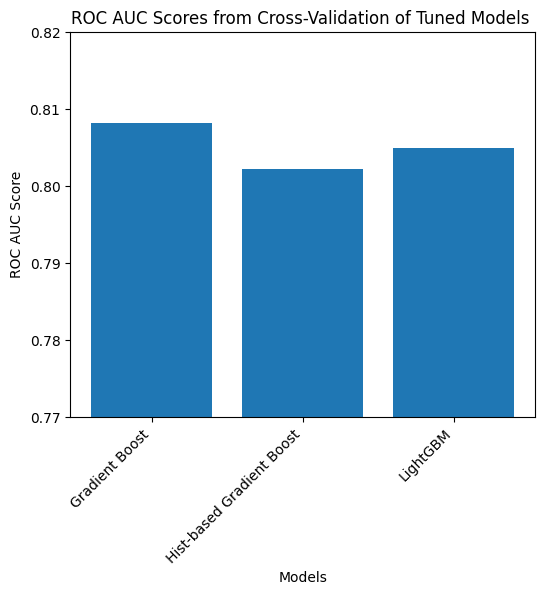

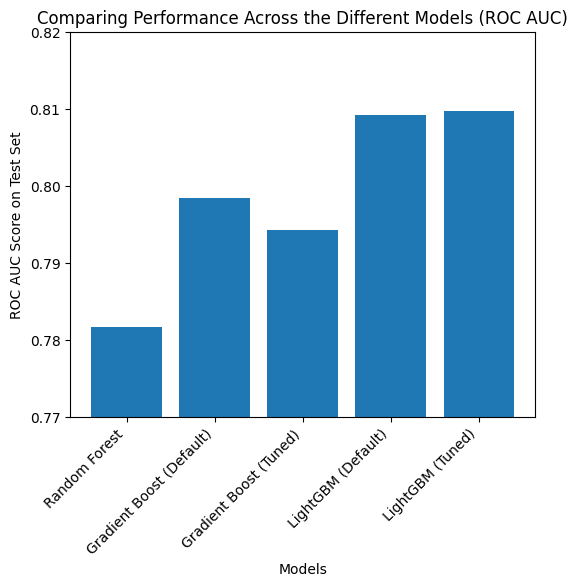

In [54]:
#Plot the ROC AUC scores for each model

models = {
    'Random Forest': rf_clf,
    'Gradient Boost (Default)': gb_clf,
    'Gradient Boost (Tuned)': best_gb,
    'LightGBM (Default)': lgb_clf,
    'LightGBM (Tuned)': best_lgb
}

tuned_models = {
    'Gradient Boost': best_gb,
    'Hist-based Gradient Boost': best_hgb,
    'LightGBM': best_lgb
}

ROC_scores_train = [gb_best_trial.value, lgb_best_trial.value, hgb_best_trial.value]

plt.figure(figsize = (6,5))
plt.bar(tuned_models.keys(), ROC_scores_train)
plt.xlabel('Models')
plt.ylabel('ROC AUC Score')
plt.title('ROC AUC Scores from Cross-Validation of Tuned Models ')
plt.xticks(rotation=45, ha='right')
plt.ylim(0.77, 0.82)
plt.show()

ROC = {} #create dict to hold the ROC for each model

for name, model in models.items():
  if name == 'Gradient Boost (Tuned)' or name == 'LightGBM (Tuned)':
    model.fit(train, train_labels.values.ravel())
    preds = model.predict_proba(test)[:,1]
    ROC[name] = roc_auc_score(test_labels, preds)

ROC_scores_test = [rf_ROC, gb_ROC, ROC['Gradient Boost (Tuned)'], lgb_ROC, ROC['LightGBM (Tuned)']]

plt.figure(figsize = (6,5))
plt.bar(models.keys(), ROC_scores_test)
plt.xlabel('Models')
plt.ylabel('ROC AUC Score on Test Set')
plt.title('Comparing Performance Across the Different Models (ROC AUC)')
plt.xticks(rotation=45, ha='right')
plt.ylim(0.77, 0.82)
plt.show()

###**Visualising Optimisation History**

In [55]:
from optuna.visualization import plot_optimization_history, plot_parallel_coordinate

In [56]:
model_studies = {
    'Gradient Boost': gb_study,
    'Hist-based Gradient Boost': hgb_study,
    'LightGBM': lgb_study
}
for name, study in model_studies.items():
  study.study_name = name

plot_optimization_history([gb_study, hgb_study, lgb_study])

In [57]:
display(plot_parallel_coordinate(gb_study))
display(plot_parallel_coordinate(hgb_study))
display(plot_parallel_coordinate(lgb_study))

###**Visualising Feature Importances**

Feature importances can be used to find which features in the decision tree were the most important

This can be determined by:
- **Impurity**: the reduction in inpurity the feature produces (averaged across all the trees in a forest)
  - used by gradient boost, random forest
- **Split**: the number of times a feature is chosen to split a node (across all trees in the forest)
  - this is the default for lightgbm

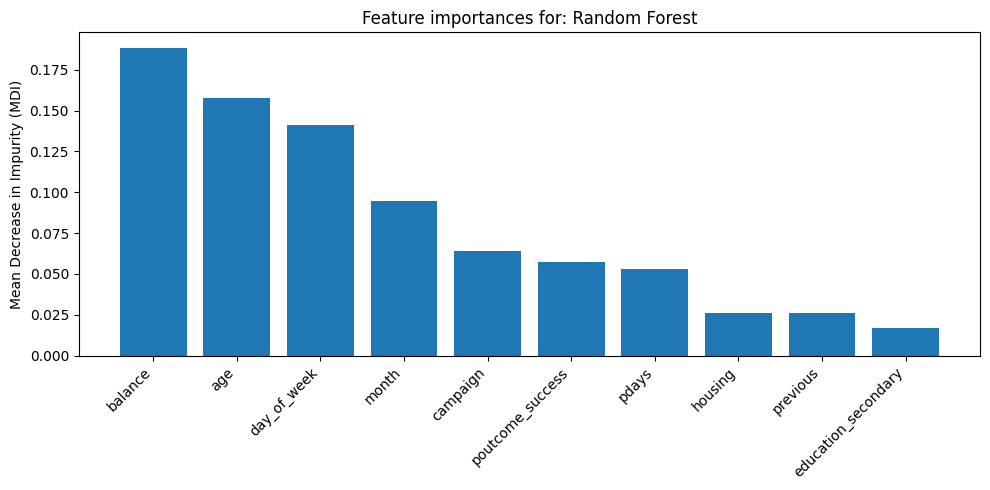

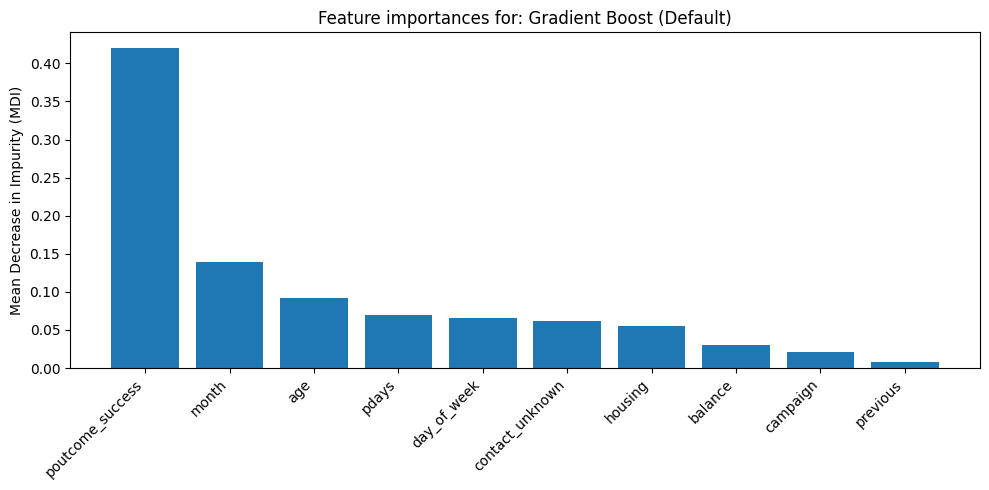

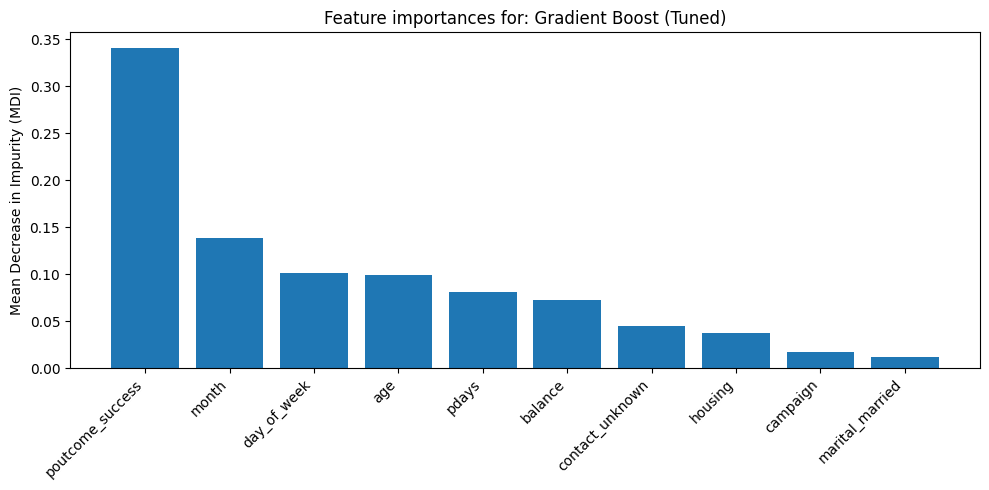

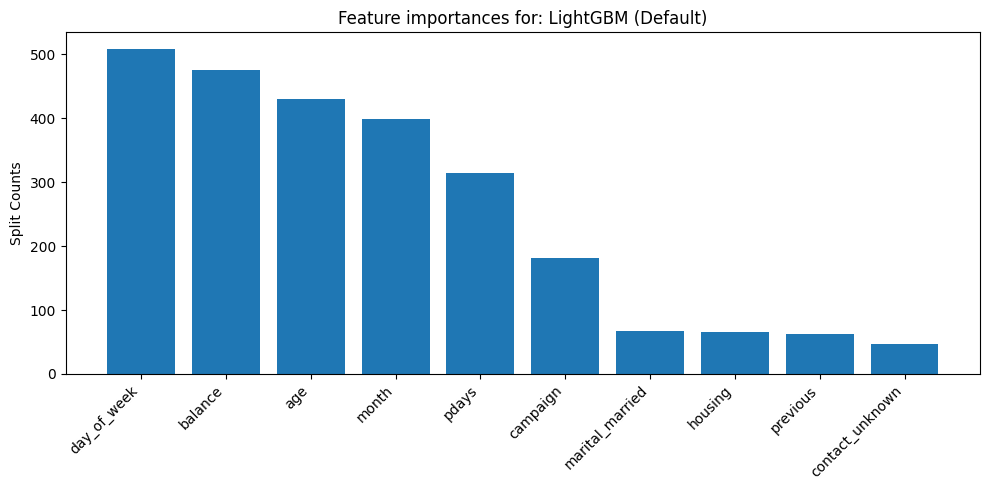

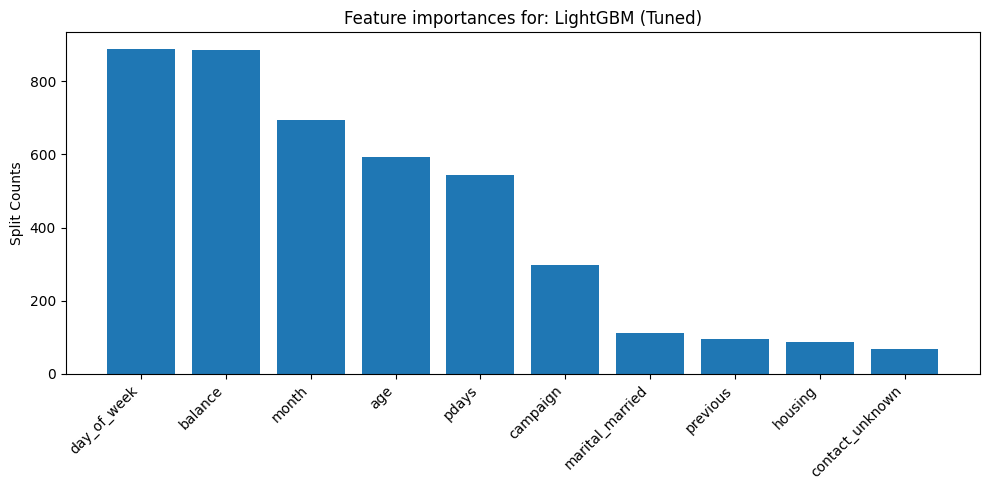

In [50]:
# Get feature names from the training set
feature_names = train.columns

for name, model in models.items():
  importances = model.feature_importances_
  sorted_idx = importances.argsort()[::-1] #[::-1] gives most important first
  top10_idx = sorted_idx[:10]
  top10_features = feature_names[top10_idx]
  top10_importances = importances[top10_idx]
  plt.figure(figsize =(10, 5))
  plt.bar(top10_features, top10_importances)
  plt.xticks(rotation=45, ha='right')
  plt.title(f'Feature importances for: {name}')
  if name == 'LightGBM (Default)' or name == 'LightGBM (Tuned)':
    plt.ylabel("Split Counts")
  else:
    plt.ylabel("Mean Decrease in Impurity (MDI)")
  plt.tight_layout()
  plt.show()

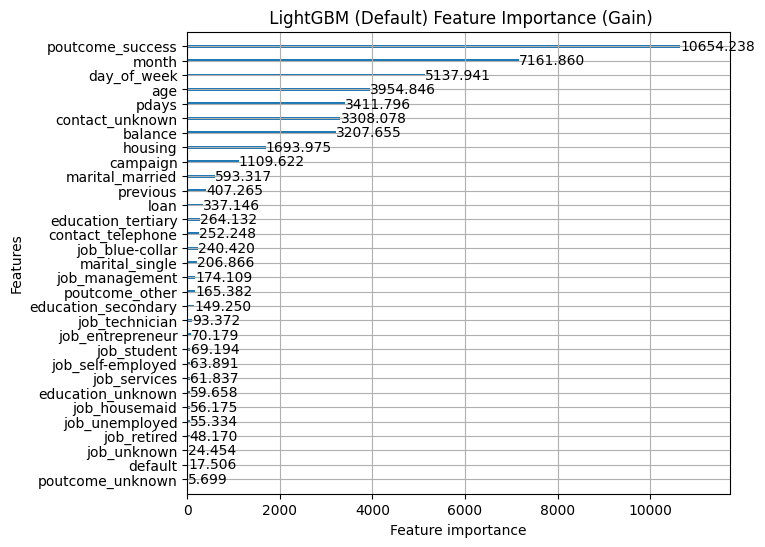

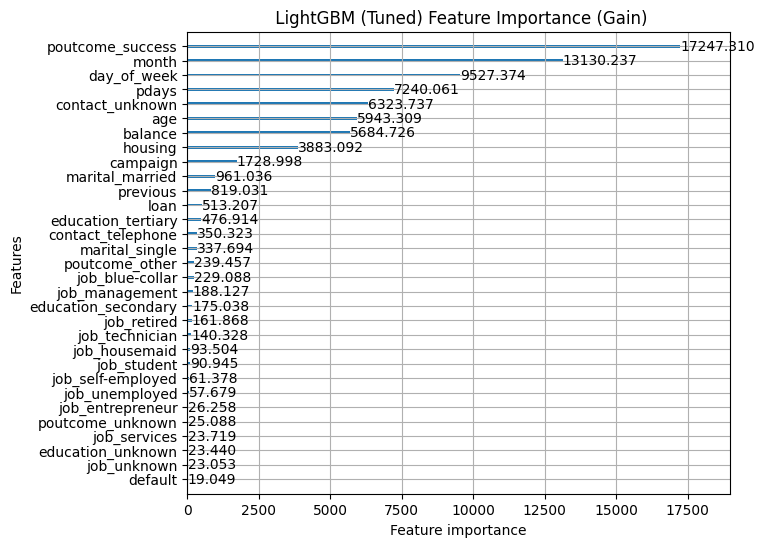

In [51]:
#LGB has its own plot_importance function, which can be used to visualise gain (in accuracy) for lgb
for name, model in models.items():
  if name == 'LightGBM (Default)' or name == 'LightGBM (Tuned)':
    lgb.plot_importance(model, importance_type="gain", figsize=(7,6), title = f" {name} Feature Importance (Gain)")
    plt.show()
  else:
    pass

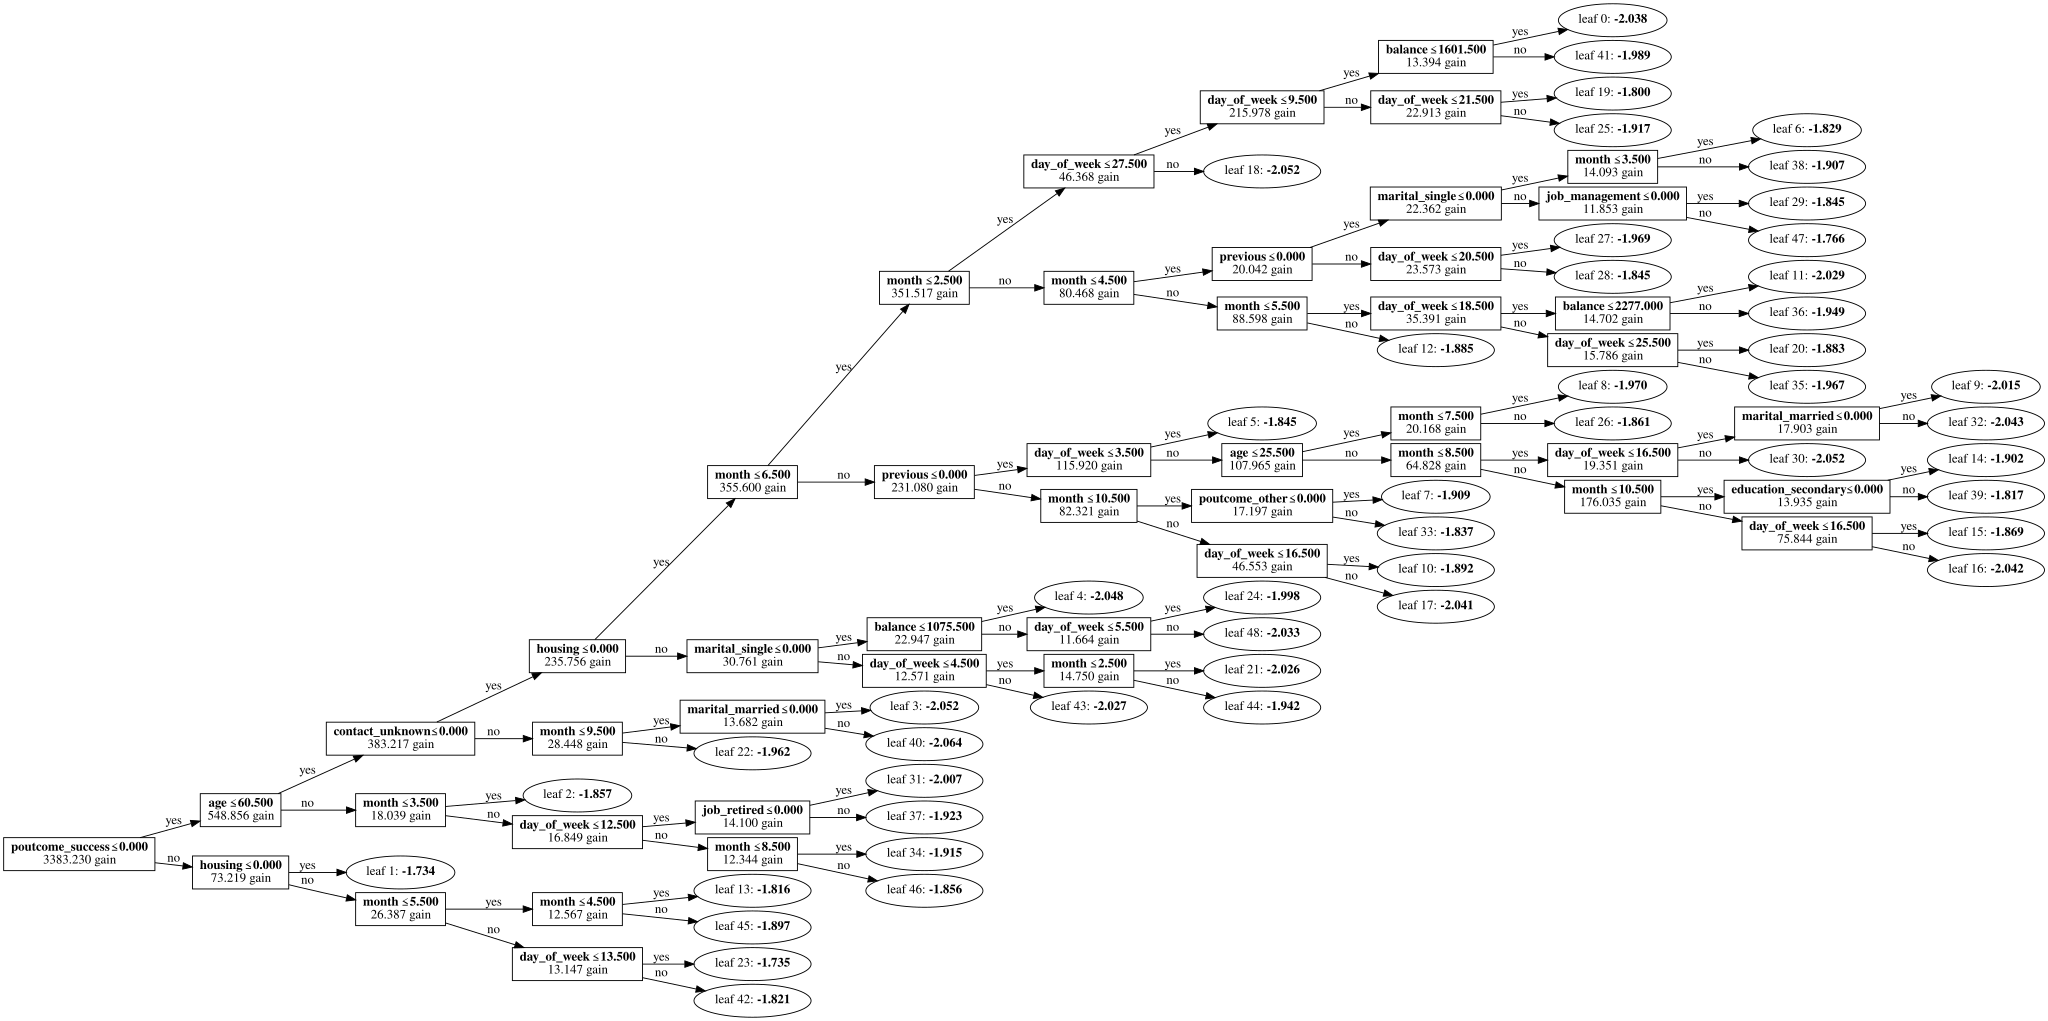

In [43]:
#Plot the first and last estimators in the model
lgb_first_estimator = lgb.create_tree_digraph(best_lgb, tree_index=0, show_info=["split_gain"])
display(lgb_first_estimator)

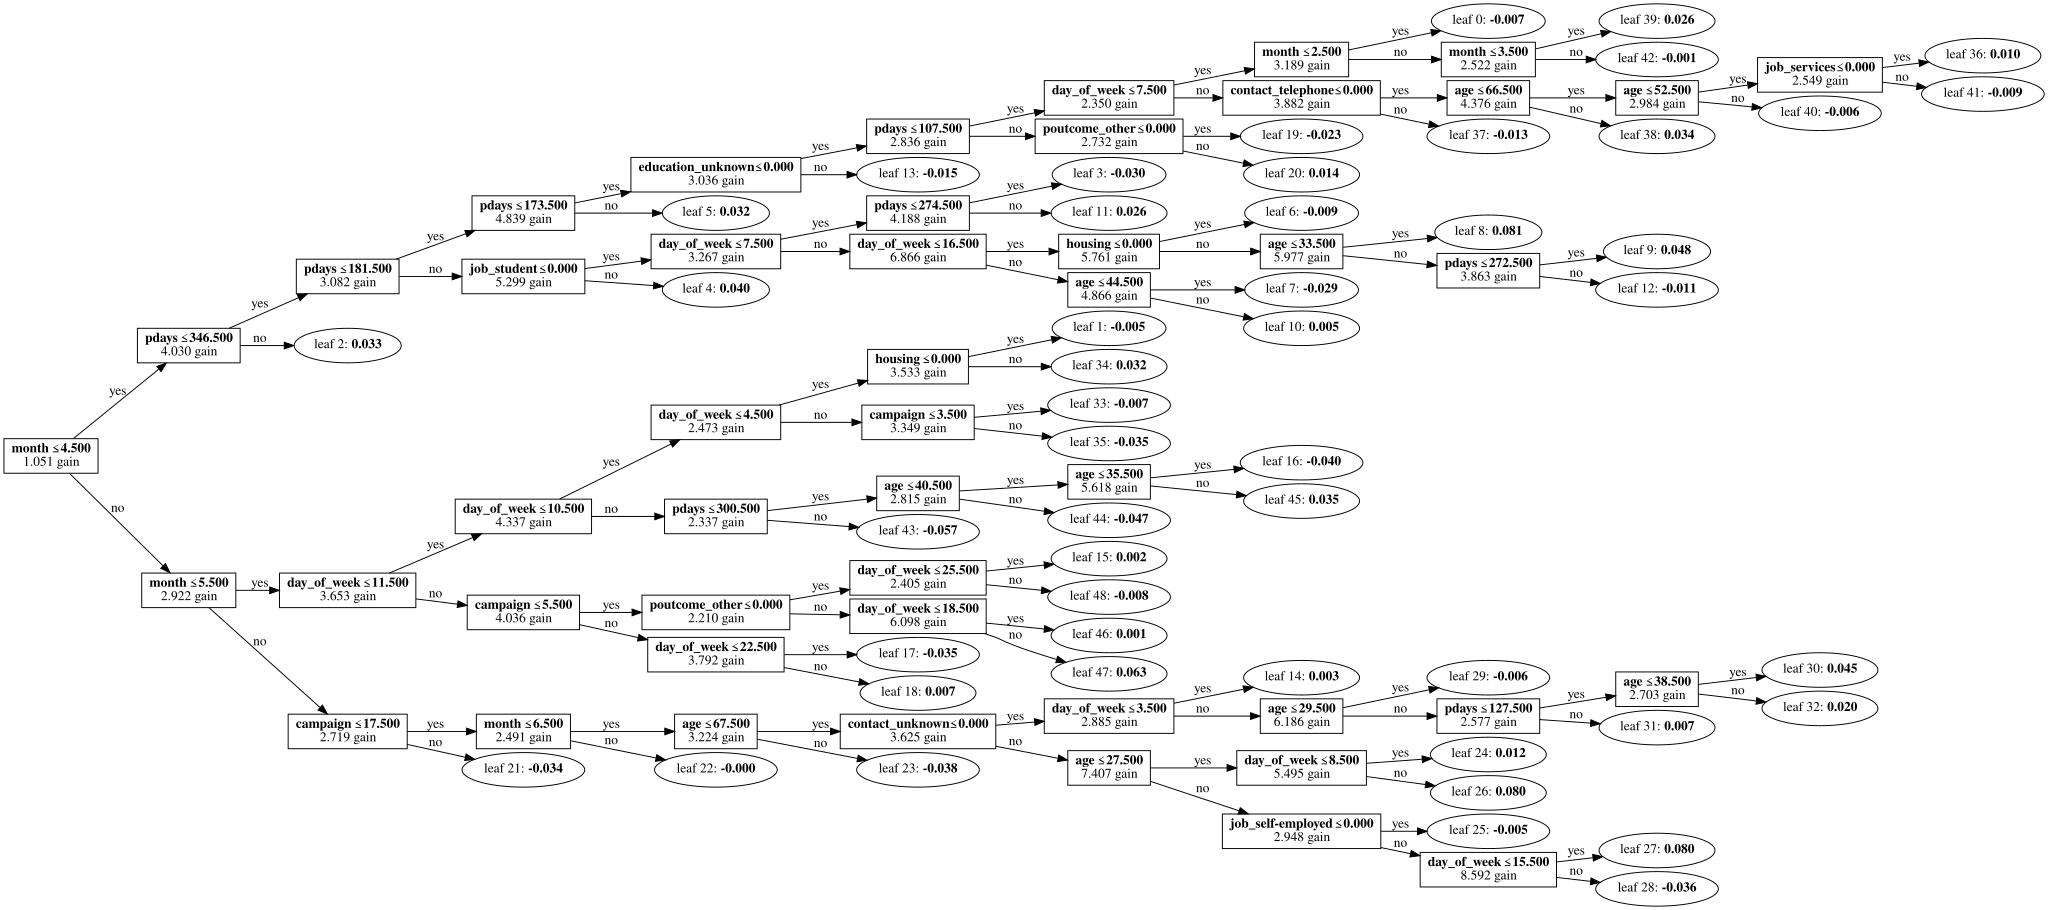

In [44]:
lgb_last_estimator = lgb.create_tree_digraph(best_lgb, tree_index=99, show_info=["split_gain"])
display(lgb_last_estimator)

###**Plotting Partial Dependence Plots**

A **Partial Dependence Plot (PDP)** is a visualisation tool that shows how a specific feature affects your model’s predictions, while holding all other features constant.

**PDP Approach** (example using predictor: ‘age’)
1) Takes the entire test dataset, changes everyone’s age to 20 and runs them through the model, recording average predicted probability
2) Changes everyone’s age to 25, runs them through, records new average
3) Process repeated across the entire range of ages
4) Averages plotted on a line chart

We can use a PCP to determine what values of 'age' and 'balance', two important features (as identified above) result in a higher chance of resulting in a 'yes' outcome.

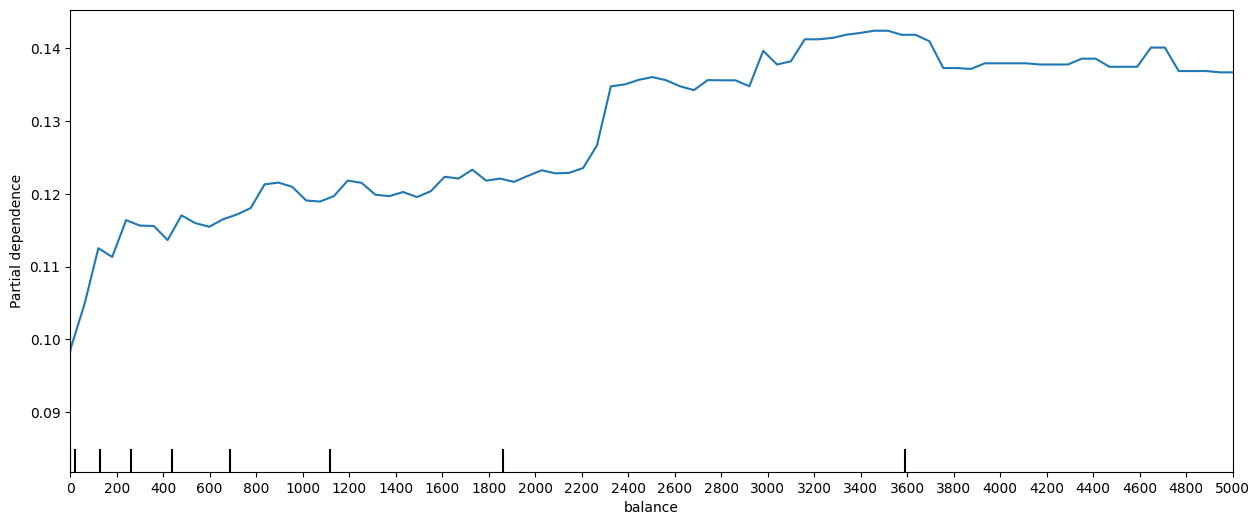

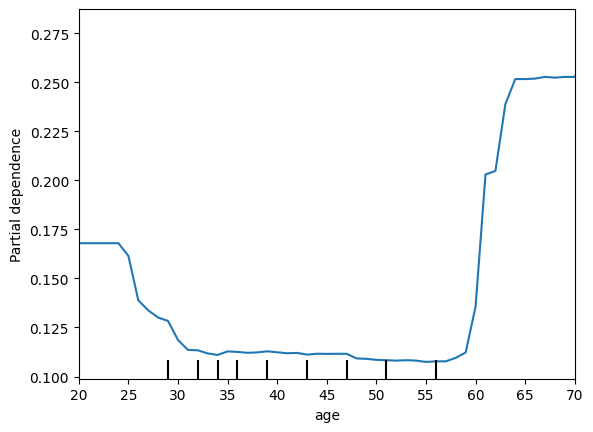

In [69]:
from sklearn.inspection import PartialDependenceDisplay
import matplotlib.pyplot as plt
import numpy as np

# Generate individual plots
fig_balance = PartialDependenceDisplay.from_estimator(best_lgb, test, features=["balance"])
fig_balance.axes_[0, 0].set_xlim(0, 5000)
fig_balance.axes_[0, 0].set_xticks(np.arange(0, 5001, 200))
fig_balance.figure_.set_size_inches(15, 6)

fig_age = PartialDependenceDisplay.from_estimator(best_lgb, test, features=["age"])
fig_age.axes_[0, 0].set_xlim(20, 70)
fig_age.axes_[0, 0].set_xticks(np.arange(20, 71, 5))

plt.show()

####**Conclusion**

**Looking back at the Objectives:**

**1)To compare the accuracy of different boosting models and  determine the optimal model for prediction**

Light GBM performs the best of all the boosting/ classification techniques used. This is likely because it encourages tree complexity, by encouraging higher number of leaves and depth, but encorporating features like `min_impurity_decrease` to ensure better leaves are formed/ increase accuracy.

LightGBM also has faster training times, due to its more efficient memory storage (use of the object Dataset) and techniques such as EBF and GOSS.

**Overall**, LightGBM should be selected as the optimal boosting method for better performance.

**2)To determine which client groups to target, based on the features of the clients that did subscribe**

Based on the feature importances, the features that contribute the most to determining yes/no are the **balance** and **age** of the client, as well as **day of the week** (last contact day of the week).

**For `balance`:**\
The PCP shows that a big jump in partial dependence occurs when clients have an **average yearly balance >2200 euros**. These clients should therefore be targeted to maximise a 'yes' outcome.

**For `age`**:\
The PCP shows that generally age didn't have much of an effect, it likely was a feature with high importance as the dataset had a wide spread of ages (shown by the decile ticks). However, it appears that clients are **aged <30** have a higher chance of subscribing. Although it is important to note that this made be due to chance.


For future calls, the bank can therefore aim to target clients with:
- Average yearly balance: >2200 euros
- Age: <30

In order to maximise the chance of the client subscribing. This is useful as it allows marketing efforts to be more targeted, which saves the bank time and resources.


